In [1]:
import glob
from joblib import Parallel, delayed
#from catalog_plotter import plot_var, get_array
import numpy as np
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import datetime
from astropy.time import Time
import utils

In [2]:
def get_simfield(sim, vars, date, t):

    sim_file = glob.glob(map.remap[sim] + date + '*')

    if len(sim_file) > 1: print('ERROR!!!!! More than one file detected with these specs')
    
    # Crack open the first file and read the convective top information, then loop over the rest
    sim_nc = nc4.Dataset(sim_file[0])
    simlon = sim_nc.variables['lon'][:]
    simlat = sim_nc.variables['lat'][:]
    hyam = sim_nc.variables['hyam'][:]
    hybm = sim_nc.variables['hybm'][:]
    date = sim_nc.variables['date'][t]
    datesec = sim_nc.variables['datesec'][t]
    simfield = np.squeeze(sim_nc.variables[vars[0]][t,:])  # Maybe this will account for the fact that some plot fields have 3D and others have 4D?
    if len(vars) > 1: 
        for v in range(len(vars)-1):
            curr_simfield = np.squeeze(sim_nc.variables[vars[v+1]][t,:])
            simfield = simfield + curr_simfield

    datestr = str(date) + '_' + str(int(datesec/3600.)).zfill(2) + 'Z'#_' + str(int((datesec/60.) % 60)).zfill(2) + 'min'    
    
    print('Simulated field shape = ', np.shape(simfield))

    return simfield, simlon, simlat, hyam, hybm, datestr

def interp_to_prslev(var_arr, PS_arr, lon, lat, hyam, hybm, plot_lev):

    #print('Interpolating ' + var_name + ' to the ' + str(plot_lev) + 'hPa surface at ' + valid_datestr)

    if len(np.shape(var_arr)) == 3: 
    
        var_plev = np.zeros((len(lat), len(lon)))-999
    
        for ln in range(len(lon)):
            for lt in range(len(lat)):
    
                curr_PS = PS_arr[lt,ln]
                curr_plev = (hyam*1.0e5 + hybm*curr_PS)/100.  
    
                plev_f = interp1d(curr_plev, np.squeeze(var_arr[:,lt,ln]), bounds_error=False, fill_value=-999)
    
                var_plev[lt,ln] = plev_f(plot_lev)

    elif len(np.shape(var_arr)) == 2: var_plev = var_arr
    
    return var_plev

def get_ACCLIP_merge_data(OBSROOT, FLT_DATES, var_str):
    
    OBSvar = []

    for FLT_DATE in FLT_DATES:
    
        AIRFILE = glob.glob(OBSROOT + '*' + FLT_DATE + '*.ict')[0]     
        AIRheaders = np.loadtxt(AIRFILE, delimiter=',', usecols = (0), dtype='str')
        AIRdata = np.loadtxt(AIRFILE, delimiter=',', skiprows=int(AIRheaders[0]))  # Read the file
        OBSvar.extend(AIRdata[:,int(list(AIRheaders).index(var_str))-11])
        
    return np.asarray(OBSvar)

def draw_box(ax, left, right, bot, top, col, thk):
    ax.plot([left, left], [bot, top], color=col, linewidth=thk)
    ax.plot([right, right], [bot, top], color=col, linewidth=thk)
    ax.plot([left, right], [bot, bot], color=col, linewidth=thk)
    ax.plot([left, right], [top, top], color=col, linewidth=thk) 
    
def plot_map(ax, lon, lat, var_plot, var_name, plot_lev, sim, extent, conv_dom, datestr, let):

    GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
    GV_FLT_DATES = ['20220819']
    ACCLIP_GV_lon = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLON') 
    ACCLIP_GV_lat = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLAT')     

    WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
    WB_FLT_DATES = ['20220819']
    ACCLIP_WB_lon = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LONG_MMS') 
    ACCLIP_WB_lat = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LAT_MMS') 
    
    ax.set_extent(extent)

    ax.coastlines()
    ax.set_title(let + sim + ' ' + var_name + ' at ' + str(plot_lev) + 'hPa on ' + datestr)
    #ax.set_title(sim)
    
    cbar_lev, cbar_rgb, norm = utils.get_colorbar(var_name, plot_lev, 2)  # 0 standard, 1 weird, 2 reds

    cf = ax.contourf(lon, lat, var_plot, levels=cbar_lev, norm=norm, cmap=cbar_rgb, extend='both')

    ax.scatter(ACCLIP_GV_lon, ACCLIP_GV_lat, s=0.5, color='k')
    ax.scatter(ACCLIP_WB_lon, ACCLIP_WB_lat, s=0.5, color='k') 

    draw_box(ax, conv_dom[0], conv_dom[1], conv_dom[2], conv_dom[3], [0.5,0.5,0.5], 1)

    return cf, cbar_lev

In [3]:

sims = ['2022_E5-strong','2022_M2-strong']
var = 'q'
plot_lev = 850.
extent = [105,145,25,45]  # August 19 box, full map boundaries
conv_dom = [110,122,36,42]   # Tiny box over the uplift region


In [4]:

# Simulation output
simvar0, simlon, simlat, hyam, hybm, datestr0 = get_simfield(sims[0], pc.var_info[var]['vars'],  '2022-08-18', 3)
simPS0,  simlon, simlat, hyam, hybm, datestr0 = get_simfield(sims[0], ['PS'], '2022-08-18', 3)
simvar1, simlon, simlat, hyam, hybm, datestr1 = get_simfield(sims[1], pc.var_info[var]['vars'],  '2022-08-18', 3)
simPS1,  simlon, simlat, hyam, hybm, datestr1 = get_simfield(sims[1], ['PS'], '2022-08-18', 3)

# Attempt to use the same functions to extract ERA5
ERA5var, ERA5lon, ERA5lat, hyam, hybm, datestrE = get_simfield('ERA5_f09_32L', pc.var_info[var]['vars'],  '2022-08-18-43200', 0)
ERA5PS, ERA5lon, ERA5lat, hyam, hybm, datestrE = get_simfield('ERA5_f09_32L', ['PS'],  '2022-08-18-43200', 0)
M2var, M2lon, M2lat, hyam, hybm, datestrE = get_simfield('MERRA-2_f09_32L', pc.var_info[var]['vars'],  '2022-08-18-43200', 0)
M2PS, M2lon, M2lat, hyam, hybm, datestrM = get_simfield('MERRA-2_f09_32L', ['PS'],  '2022-08-18-43200', 0)

simvar0_plot = interp_to_prslev(np.squeeze(simvar0), np.squeeze(simPS0), simlon, simlat, hyam, hybm, plot_lev)*pc.var_info[var]['mod']
simvar1_plot = interp_to_prslev(np.squeeze(simvar1), np.squeeze(simPS1), simlon, simlat, hyam, hybm, plot_lev)*pc.var_info[var]['mod']
ERA5var_plot = interp_to_prslev(np.squeeze(ERA5var), np.squeeze(ERA5PS), simlon, simlat, hyam, hybm, plot_lev)*pc.var_info[var]['mod']
M2var_plot = interp_to_prslev(np.squeeze(M2var), np.squeeze(M2PS), simlon, simlat, hyam, hybm, plot_lev)*pc.var_info[var]['mod']


Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)
Simulated field shape =  (32, 192, 288)
Simulated field shape =  (192, 288)


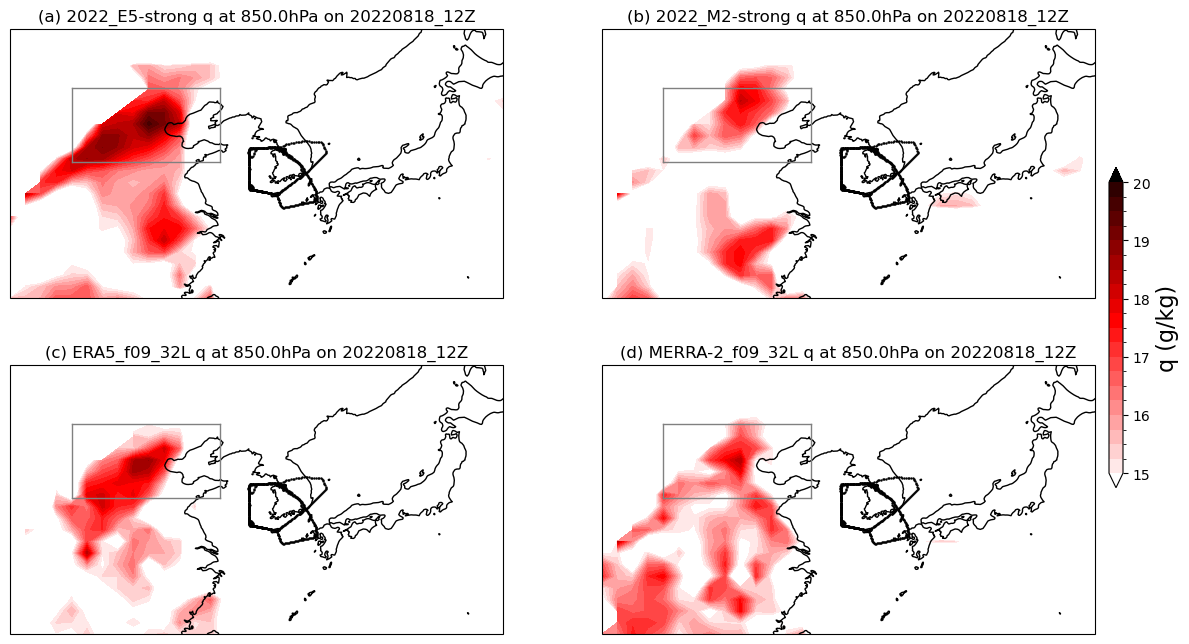

In [5]:

fig = plt.figure(figsize=(14,8))
ax0 = fig.add_subplot(2,2,1,projection=ccrs.PlateCarree())
ax1 = fig.add_subplot(2,2,2,projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(2,2,3,projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(2,2,4,projection=ccrs.PlateCarree())

cf0, cbar_lev0 = plot_map(ax0, simlon, simlat, simvar0_plot, var, plot_lev, sims[0], extent, conv_dom, datestr0, '(a) ')
cf1, cbar_lev1 = plot_map(ax1, simlon, simlat, simvar1_plot, var, plot_lev, sims[1], extent, conv_dom, datestr1, '(b) ')
cfE, cbar_levE = plot_map(ax2, ERA5lon, ERA5lat, ERA5var_plot, var, plot_lev, 'ERA5_f09_32L', extent, conv_dom, datestrE, '(c) ')
cfM, cbar_levM = plot_map(ax3, M2lon, M2lat, M2var_plot, var, plot_lev, 'MERRA-2_f09_32L', extent, conv_dom, datestrM, '(d) ')

cbax0 = fig.add_axes([0.91,0.30,0.01,0.40])
cbar0 = plt.colorbar(cf0, cax = cbax0, orientation='vertical', ticks = cbar_lev0[::4], fraction=0.05)
cbar0.set_label(var + ' (' + pc.var_info[var]['unit'] + ')', fontsize=16)
